# Assignment 4: Intensity Transformations

**Objective:** Apply point-wise intensity transformations to a grayscale image:
1. Log transformation
2. Power-law (gamma) transformation
3. Piecewise-linear contrast stretching

> The input image is generated in code (no external image files needed). Settings that used to be typed in with `input()` are now variables at the top of each cell, so the notebook runs top to bottom without prompts.

In [1]:
import math
import cv2
import numpy as np
import matplotlib.pyplot as plt


def create_demo_image(size=128, seed=42):
    """Build a grayscale test image (gradient + shapes + texture) with NumPy and OpenCV."""
    rng = np.random.default_rng(seed)

    # Smooth horizontal gradient as the background
    canvas = np.tile(np.linspace(40, 140, size, dtype=np.float32), (size, 1))

    # Bright square, dark circle and a mid-grey diagonal line give us edges and flat regions
    cv2.rectangle(canvas, (size // 8, size // 8), (size // 2, size // 2), 220, -1)
    cv2.circle(canvas, (int(size * 0.70), int(size * 0.65)), size // 5, 30, -1)
    cv2.line(canvas, (0, size - 1), (size - 1, size // 3), 180, 3)

    # Light texture so the image is not perfectly smooth
    canvas += rng.normal(0, 4, canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)


def show_images(images, titles, columns=None, figsize=None):
    """Display several grayscale images side by side with titles."""
    columns = columns or len(images)
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=figsize or (4 * columns, 4 * rows))
    for index, (picture, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(picture, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## Part A: Log transformation
`s = c * log(1 + r)` with `c = L / log(L + 1)`, then rescaled to 0-255. It expands dark intensities and compresses bright ones.

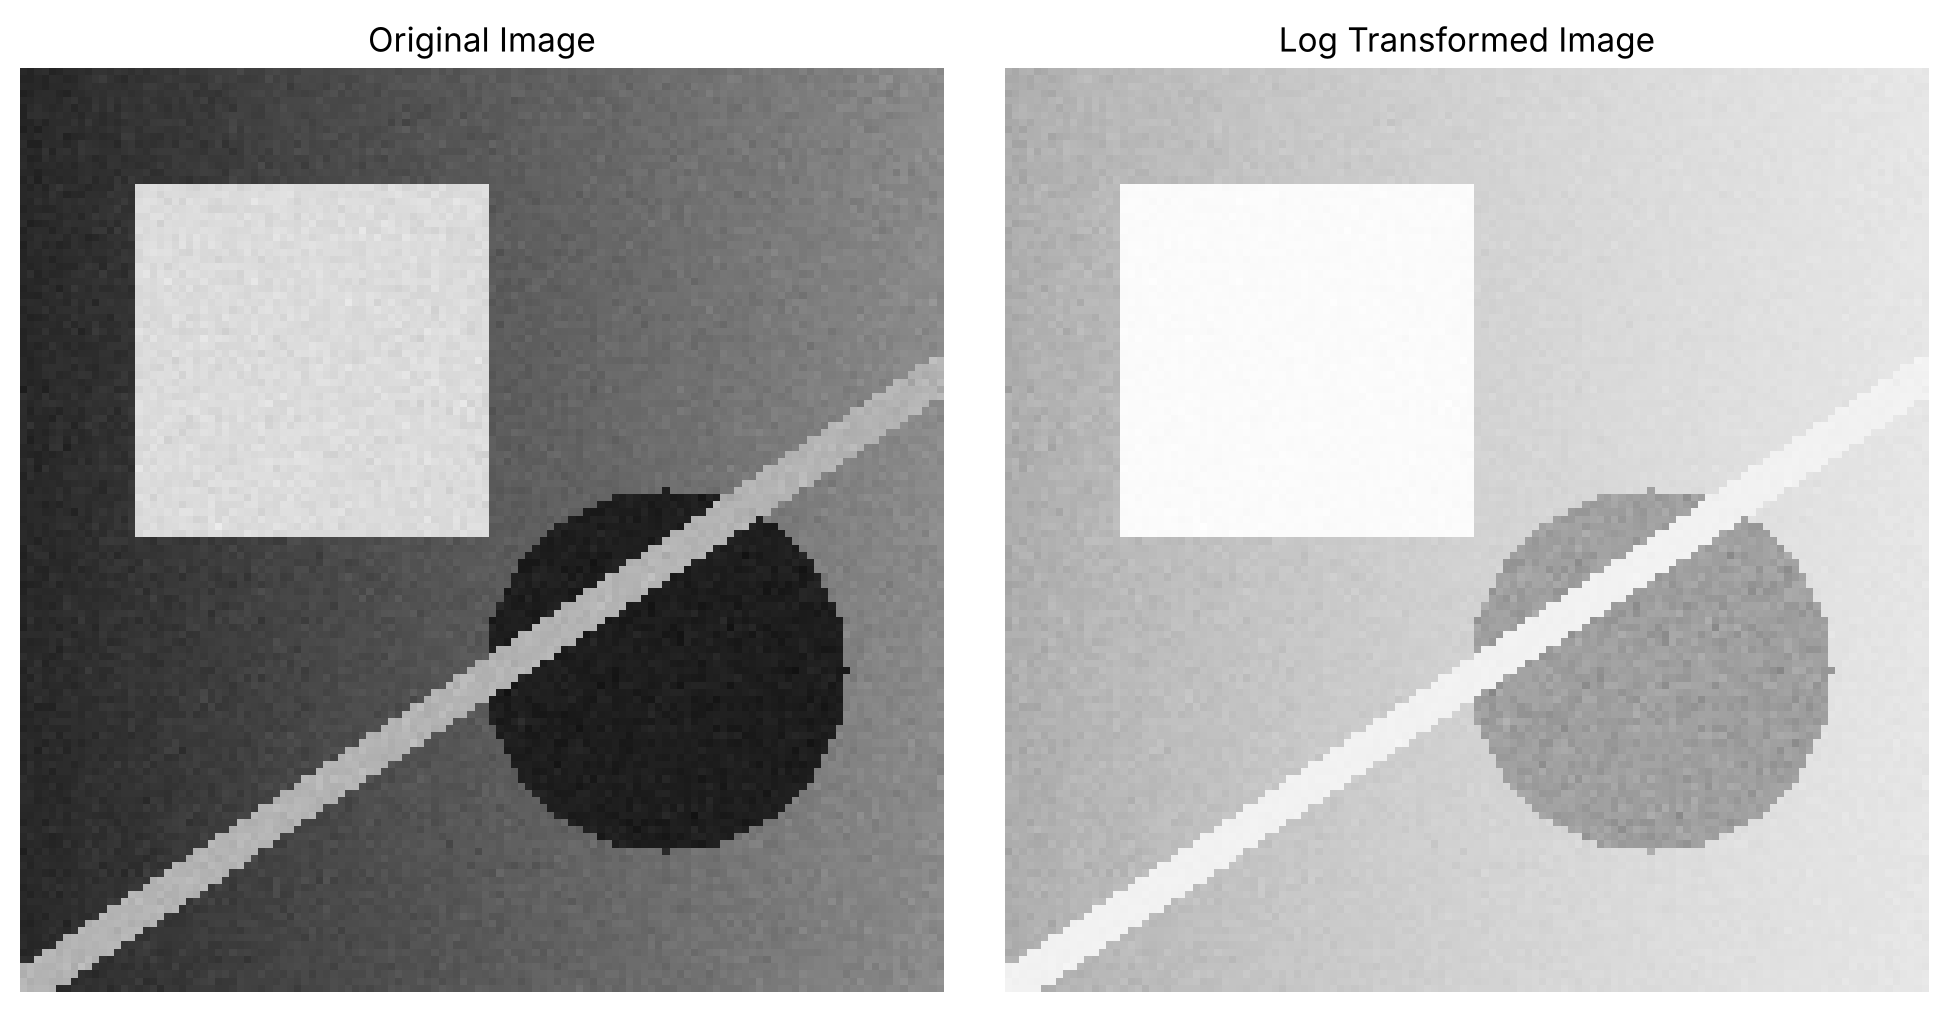

In [2]:
grayscale_image = create_demo_image()

NUM_LEVELS = 256
log_constant = NUM_LEVELS / math.log(NUM_LEVELS + 1)

log_result = np.zeros(grayscale_image.shape, dtype=np.float32)
for row in range(grayscale_image.shape[0]):
    for col in range(grayscale_image.shape[1]):
        log_result[row][col] = log_constant * math.log(1 + float(grayscale_image[row][col]))

log_result = (log_result / log_result.max()) * 255
log_image = np.uint8(log_result)

show_images([grayscale_image, log_image], ["Original Image", "Log Transformed Image"], figsize=(10, 5))

## Part B: Power-law (gamma) transformation
`s = c * r^gamma` with `c = 1`, then rescaled to 0-255. Gamma < 1 brightens the image, gamma > 1 darkens it. Try different values.

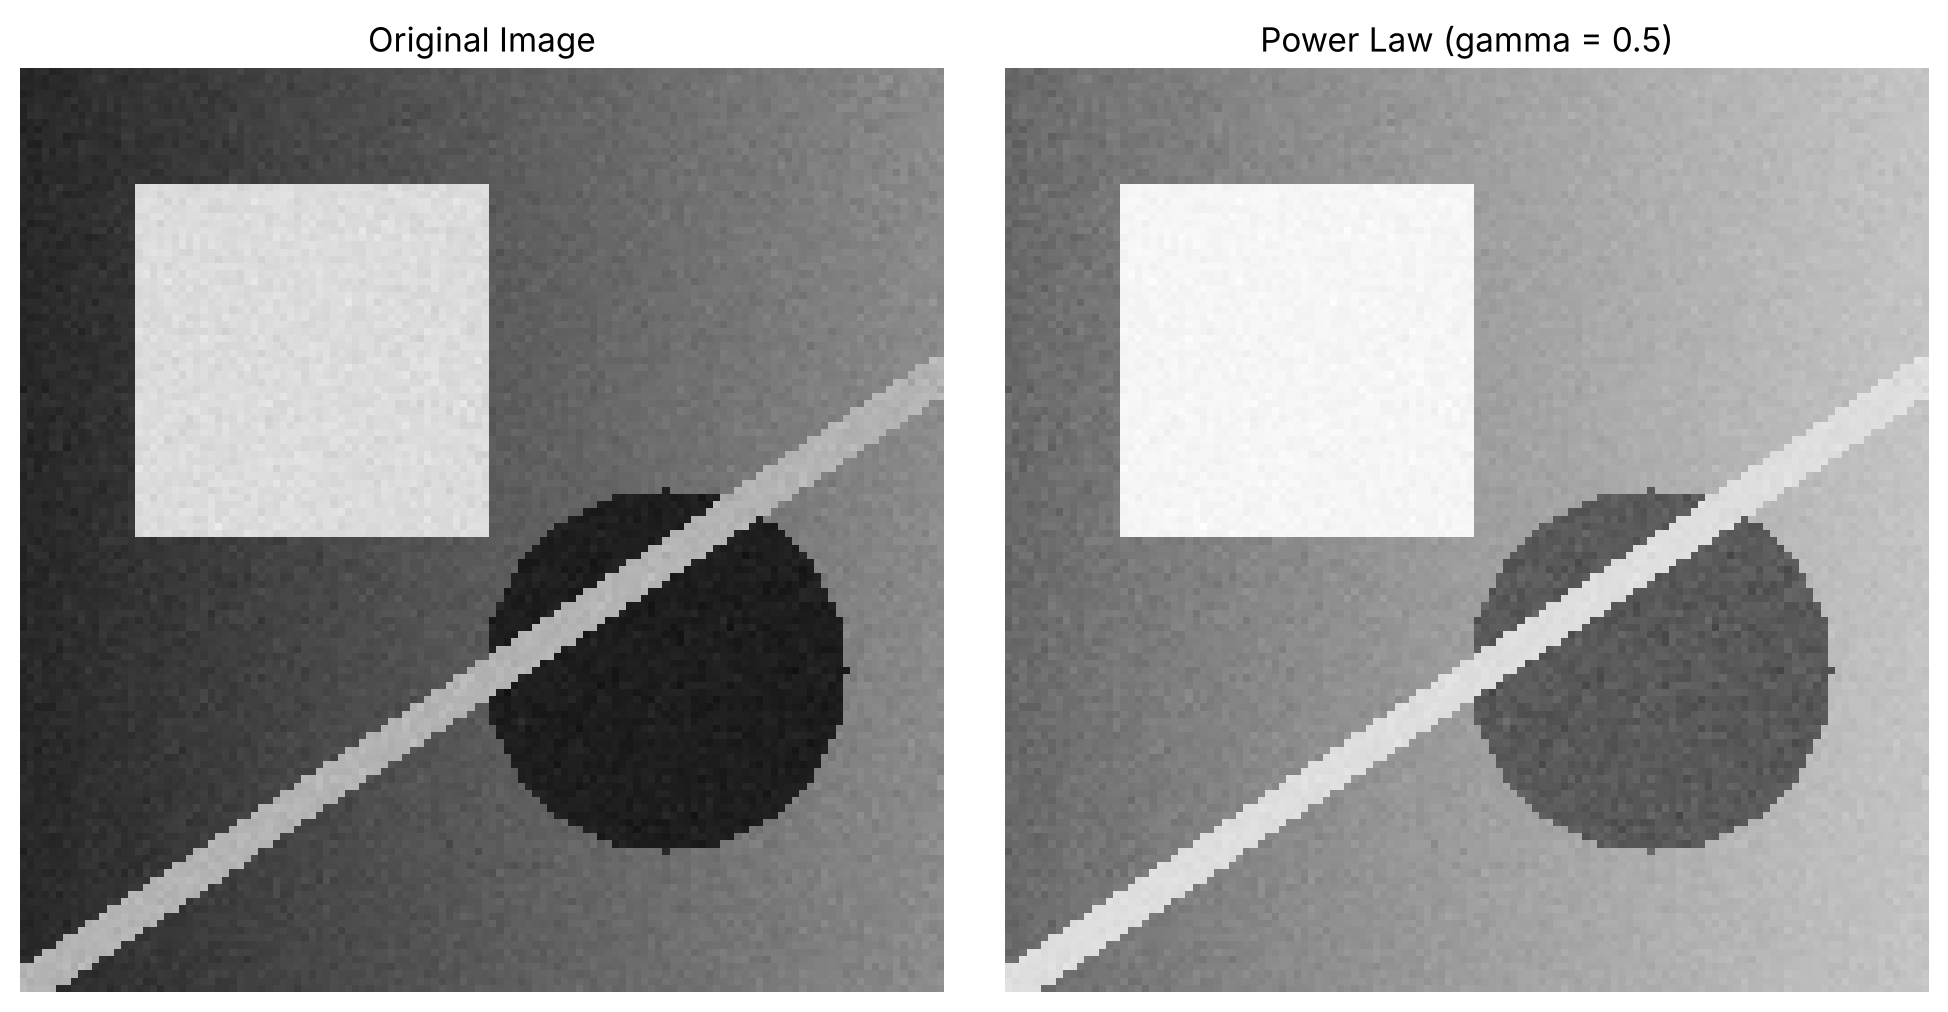

In [3]:
GAMMA = 0.5   # change me

grayscale_image = create_demo_image()
power_constant = 1

power_result = np.zeros(grayscale_image.shape, dtype=np.float32)
for row in range(grayscale_image.shape[0]):
    for col in range(grayscale_image.shape[1]):
        power_result[row][col] = power_constant * (float(grayscale_image[row][col]) ** GAMMA)

power_result = (power_result / power_result.max()) * 255
gamma_image = np.uint8(power_result)

show_images([grayscale_image, gamma_image], ["Original Image", f"Power Law (gamma = {GAMMA})"], figsize=(10, 5))

## Part C: Contrast stretching
Pixels with input intensity in `[INPUT_LOW, INPUT_HIGH]` are linearly mapped to `[OUTPUT_LOW, OUTPUT_HIGH]`; pixels outside that range are left unchanged. Values are converted to `float` for the arithmetic to avoid `uint8` overflow.

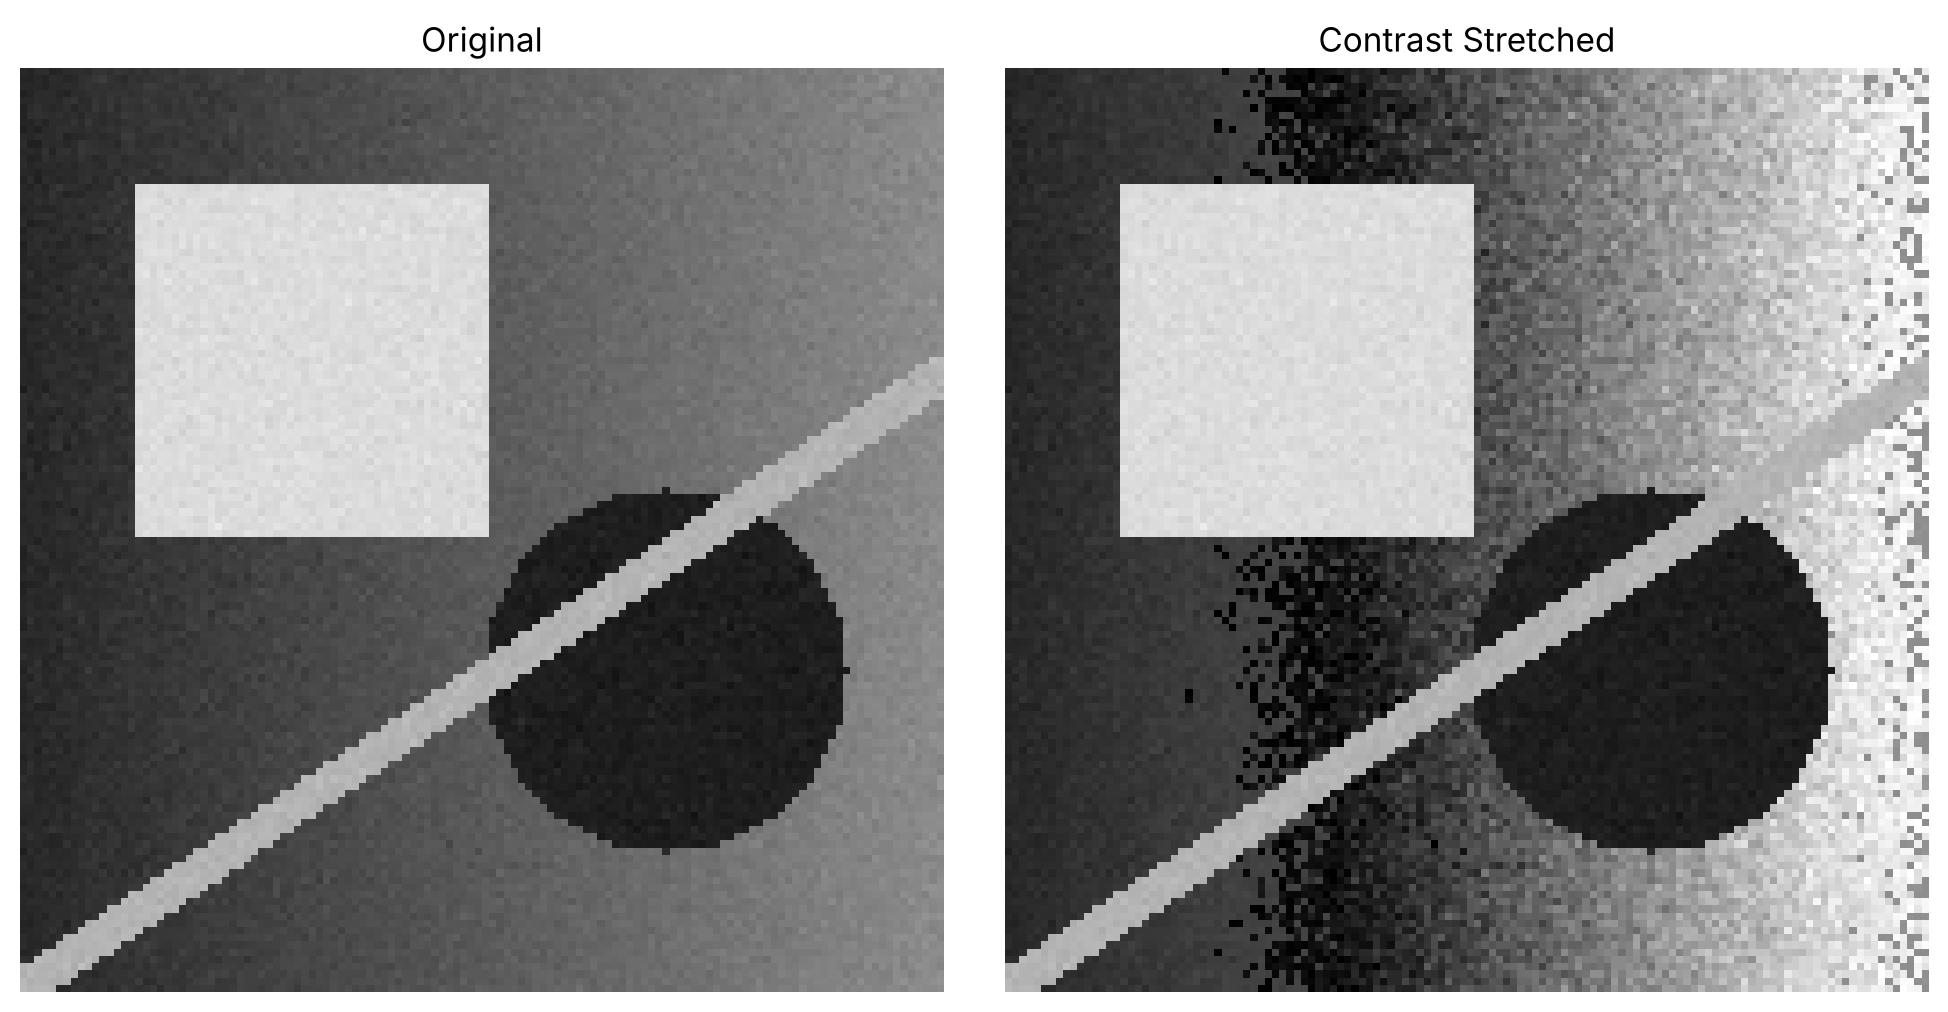

In [4]:
INPUT_LOW, INPUT_HIGH = 70, 140     # change me
OUTPUT_LOW, OUTPUT_HIGH = 0, 255    # change me

grayscale_image = create_demo_image()
stretched_image = grayscale_image.copy()

for row in range(grayscale_image.shape[0]):
    for col in range(grayscale_image.shape[1]):
        pixel = float(grayscale_image[row][col])
        if INPUT_LOW <= pixel <= INPUT_HIGH:
            stretched_image[row][col] = ((pixel - INPUT_LOW) * (OUTPUT_HIGH - OUTPUT_LOW) / (INPUT_HIGH - INPUT_LOW)) + OUTPUT_LOW

show_images([grayscale_image, stretched_image], ["Original", "Contrast Stretched"], figsize=(10, 5))